# Best Optuna NN sobre `v2_nn_dense`

Este notebook toma la mejor arquitectura de redes neuronales encontrada en `5. Experimentacion NN/NN_extendido.ipynb` y la reentrena sobre los datos procesados por `10.try/02_preprocesamiento_v2_nn.ipynb`, es decir `processed/v2_nn_dense`.

La comparación principal es contra el `best_optuna` original entrenado sobre `processed/i1`.


In [1]:
from __future__ import annotations

import json
import os
import shutil
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

BEST_OPTUNA_REFERENCE = {
    "dataset": "i1_best_optuna_reference",
    "source": "5.Experimentacion NN/NN_extendido",
    "n_hidden": 2,
    "n_units": 160,
    "learning_rate": 0.0008960785365368125,
    "batch_size": 256,
    "first_layer_wider": True,
    "epochs_ran": 16,
    "loss": 0.392262,
    "accuracy": 0.8214,
    "auc": 0.9050,
    "precision": 0.7025,
    "recall": 0.8304,
}


I0000 00:00:1777684835.940838   27457 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1777684835.998233   27457 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1777684837.742447   27457 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


def load_v2_nn_dense_dataset() -> dict[str, object]:
    project_root = find_project_root()
    processed_dir = project_root / "data" / "higgs-boson" / "processed" / "v2_nn_dense"
    if not processed_dir.exists():
        raise FileNotFoundError(f"No se encontró el directorio procesado: {processed_dir}")

    metadata = json.loads((processed_dir / "metadata.json").read_text())
    label_map = {"b": 0, "s": 1}

    X_train = pd.read_csv(processed_dir / "X_train_processed.csv").astype(np.float32)
    X_valid = pd.read_csv(processed_dir / "X_valid_processed.csv").astype(np.float32)
    X_test = pd.read_csv(processed_dir / "X_test_processed.csv").astype(np.float32)
    y_train = pd.read_csv(processed_dir / "y_train.csv")["Label"].map(label_map).astype(np.int8)
    y_valid = pd.read_csv(processed_dir / "y_valid.csv")["Label"].map(label_map).astype(np.int8)
    train_weight = pd.read_csv(processed_dir / "train_weight.csv")["Weight"].astype(np.float64)
    valid_weight = pd.read_csv(processed_dir / "valid_weight.csv")["Weight"].astype(np.float64)
    train_event_id = pd.read_csv(processed_dir / "train_event_id.csv")["EventId"].astype(np.int64)
    valid_event_id = pd.read_csv(processed_dir / "valid_event_id.csv")["EventId"].astype(np.int64)
    test_event_id = pd.read_csv(processed_dir / "test_event_id.csv")["EventId"].astype(np.int64)

    return {
        "project_root": project_root,
        "processed_dir": processed_dir,
        "metadata": metadata,
        "X_train": X_train,
        "X_valid": X_valid,
        "X_test": X_test,
        "y_train": y_train,
        "y_valid": y_valid,
        "train_weight": train_weight,
        "valid_weight": valid_weight,
        "train_event_id": train_event_id,
        "valid_event_id": valid_event_id,
        "test_event_id": test_event_id,
    }


def make_callbacks() -> list[keras.callbacks.Callback]:
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
        ),
    ]


def build_configurable_model(
    input_dim: int,
    n_hidden: int,
    n_units: int,
    learning_rate: float,
    first_layer_wider: bool,
) -> keras.Model:
    inputs = keras.layers.Input(shape=(input_dim,))
    x = inputs

    for layer_idx in range(n_hidden):
        units = n_units * 2 if first_layer_wider and layer_idx == 0 else n_units
        x = keras.layers.Dense(
            units,
            kernel_initializer="he_normal",
            use_bias=False,
        )(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)

    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


def ams_score(signal_weight: np.ndarray | float, background_weight: np.ndarray | float, br: float = 10.0) -> np.ndarray:
    signal_arr = np.asarray(signal_weight, dtype=np.float64)
    background_arr = np.asarray(background_weight, dtype=np.float64)
    radicand = 2.0 * ((signal_arr + background_arr + br) * np.log1p(signal_arr / (background_arr + br)) - signal_arr)
    return np.sqrt(np.clip(radicand, a_min=0.0, a_max=None))


def find_best_ams_threshold(
    y_true: np.ndarray,
    y_scores: np.ndarray,
    weights: np.ndarray,
    br: float = 10.0,
) -> dict[str, float | int]:
    order = np.argsort(y_scores)[::-1]
    y_sorted = y_true[order]
    score_sorted = y_scores[order]
    weight_sorted = weights[order]

    signal_cumsum = np.cumsum(np.where(y_sorted == 1, weight_sorted, 0.0))
    background_cumsum = np.cumsum(np.where(y_sorted == 0, weight_sorted, 0.0))

    candidate_mask = np.r_[score_sorted[1:] != score_sorted[:-1], True]
    candidate_indices = np.flatnonzero(candidate_mask)
    ams_values = ams_score(signal_cumsum[candidate_indices], background_cumsum[candidate_indices], br=br)

    best_position = int(np.argmax(ams_values))
    best_idx = int(candidate_indices[best_position])
    best_threshold = float(score_sorted[best_idx])

    return {
        "ams_threshold": best_threshold,
        "ams": float(ams_values[best_position]),
        "signal_weight": float(signal_cumsum[best_idx]),
        "background_weight": float(background_cumsum[best_idx]),
        "candidate_threshold_count": int(len(candidate_indices)),
    }


def plot_history(history: keras.callbacks.History, title: str) -> None:
    history_df = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df.index + 1, history_df["loss"], label="train")
    axes[0].plot(history_df.index + 1, history_df["val_loss"], label="valid")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(history_df.index + 1, history_df["auc"], label="train")
    axes[1].plot(history_df.index + 1, history_df["val_auc"], label="valid")
    axes[1].set_title(f"{title} - AUC")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


In [3]:
dataset = load_v2_nn_dense_dataset()

X_train_np = dataset["X_train"].to_numpy(dtype=np.float32)
X_valid_np = dataset["X_valid"].to_numpy(dtype=np.float32)
X_test_np = dataset["X_test"].to_numpy(dtype=np.float32)
y_train_np = dataset["y_train"].to_numpy(dtype=np.float32)
y_valid_np = dataset["y_valid"].to_numpy(dtype=np.float32)
valid_weight_np = dataset["valid_weight"].to_numpy(dtype=np.float64)

classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_np.astype(int))
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, class_weights)}

summary_df = pd.DataFrame([
    {
        "dataset": "v2_nn_dense",
        "train_rows": X_train_np.shape[0],
        "valid_rows": X_valid_np.shape[0],
        "test_rows": X_test_np.shape[0],
        "input_dim": X_train_np.shape[1],
        "train_nan_count": int(np.isnan(X_train_np).sum()),
        "valid_nan_count": int(np.isnan(X_valid_np).sum()),
        "class_weight_b": class_weight[0],
        "class_weight_s": class_weight[1],
    }
])

print(f"Directorio procesado: {dataset['processed_dir']}")
print("Resumen del dataset cargado:")
display(summary_df.round(4))
print("Metadata del preprocesado:")
for key, value in dataset["metadata"].items():
    print(f"- {key}: {value}")


Directorio procesado: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/v2_nn_dense
Resumen del dataset cargado:


,dataset,train_rows,valid_rows,test_rows,input_dim,train_nan_count,valid_nan_count,class_weight_b,class_weight_s
0,v2_nn_dense,225000,25000,550000,44,0,0,0.7606,1.4591


Metadata del preprocesado:
- variant_key: nn_dense
- variant_title: Procesamiento V2 - Pipeline para Redes Neuronales
- description: Agrega indicadores de missing, aplica imputacion jet-aware aprendida solo en train, codifica PRI_jet_num y escala features numericas con RobustScaler.
- valid_size: 0.1
- random_state: 42
- raw_feature_count: 30
- processed_feature_count: 44
- processed_train_nan_count: 0
- processed_valid_nan_count: 0
- processed_test_nan_count: 0
- expects_missing_after_processing: False


E0000 00:00:1777684841.852383   27457 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1777684841.852952   27595 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1777684841.873456   27457 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Resultados del mejor modelo de NN sobre v2_nn_dense:


,dataset,source,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,epochs_ran,accuracy,auc,loss,precision,recall,ams_threshold,ams,signal_weight,background_weight,candidate_threshold_count
0,v2_nn_dense_best_optuna,10.try/02 + best_optuna_architecture,2,160,0.0009,256,True,16,0.8258,0.9081,0.3841,0.7111,0.8283,0.9353,1.0924,16.4625,211.6688,24989


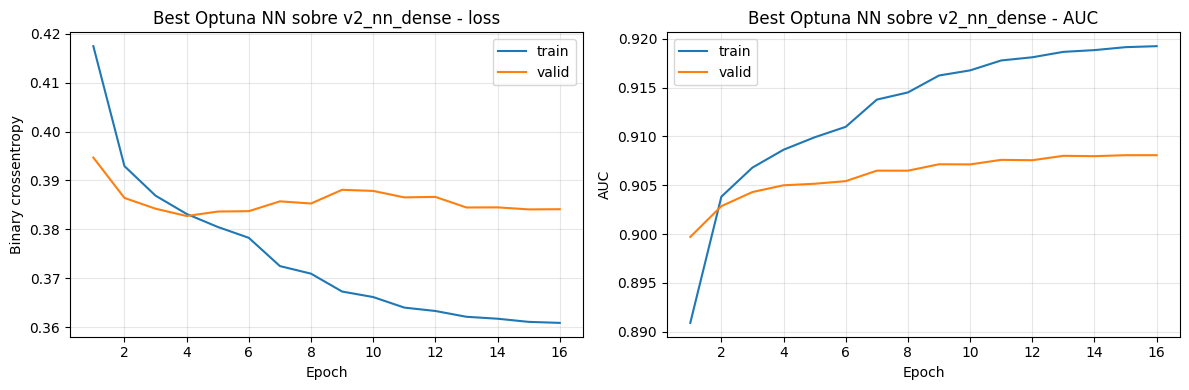

In [4]:
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model = build_configurable_model(
    input_dim=X_train_np.shape[1],
    n_hidden=int(BEST_OPTUNA_REFERENCE["n_hidden"]),
    n_units=int(BEST_OPTUNA_REFERENCE["n_units"]),
    learning_rate=float(BEST_OPTUNA_REFERENCE["learning_rate"]),
    first_layer_wider=bool(BEST_OPTUNA_REFERENCE["first_layer_wider"]),
)

history = model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=int(BEST_OPTUNA_REFERENCE["epochs_ran"]),
    batch_size=int(BEST_OPTUNA_REFERENCE["batch_size"]),
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

valid_metrics = model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
valid_scores = model.predict(X_valid_np, verbose=0).reshape(-1)
ams_info = find_best_ams_threshold(y_valid_np.astype(np.int8), valid_scores, valid_weight_np)

trained_row = {
    "dataset": "v2_nn_dense_best_optuna",
    "source": "10.try/02 + best_optuna_architecture",
    "n_hidden": int(BEST_OPTUNA_REFERENCE["n_hidden"]),
    "n_units": int(BEST_OPTUNA_REFERENCE["n_units"]),
    "learning_rate": float(BEST_OPTUNA_REFERENCE["learning_rate"]),
    "batch_size": int(BEST_OPTUNA_REFERENCE["batch_size"]),
    "first_layer_wider": bool(BEST_OPTUNA_REFERENCE["first_layer_wider"]),
    "epochs_ran": len(history.history["val_auc"]),
    **{metric: float(value) for metric, value in valid_metrics.items()},
    **ams_info,
}

trained_summary_df = pd.DataFrame([trained_row])
print("Resultados del mejor modelo de NN sobre v2_nn_dense:")
display(trained_summary_df.round(4))
plot_history(history, "Best Optuna NN sobre v2_nn_dense")


Comparación contra el best_optuna original de i1:


,dataset,source,loss,accuracy,auc,precision,recall,ams,ams_threshold,epochs_ran,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,delta_loss_vs_i1_best_optuna,delta_accuracy_vs_i1_best_optuna,delta_auc_vs_i1_best_optuna,delta_precision_vs_i1_best_optuna,delta_recall_vs_i1_best_optuna
0,i1_best_optuna_reference,5.Experimentacion NN/NN_extendido,0.3923,0.8214,0.9050,0.7025,0.8304,NaN,NaN,16,2,160,0.0009,256,True,0.0000,0.0000,0.0000,0.0000,0.0000
1,v2_nn_dense_best_optuna,10.try/02 + best_optuna_architecture,0.3841,0.8258,0.9081,0.7111,0.8283,1.0924,0.9353,16,2,160,0.0009,256,True,-0.0081,0.0044,0.0031,0.0086,-0.0021


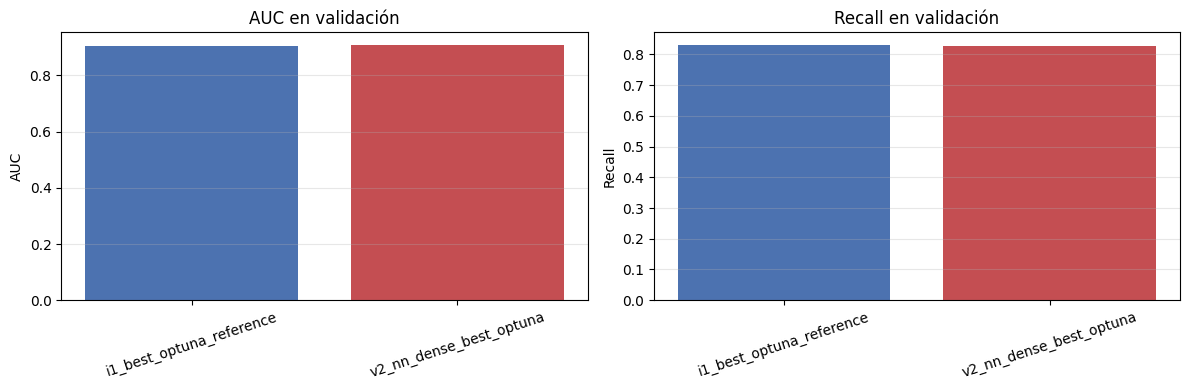

In [5]:
reference_row = {
    **BEST_OPTUNA_REFERENCE,
    "ams": np.nan,
    "ams_threshold": np.nan,
    "signal_weight": np.nan,
    "background_weight": np.nan,
    "candidate_threshold_count": np.nan,
}
comparison_df = pd.DataFrame([reference_row, trained_row])

baseline_row = comparison_df.loc[comparison_df["dataset"] == "i1_best_optuna_reference"].iloc[0]
for metric in ["loss", "accuracy", "auc", "precision", "recall"]:
    comparison_df[f"delta_{metric}_vs_i1_best_optuna"] = comparison_df[metric] - float(baseline_row[metric])

comparison_columns = [
    "dataset",
    "source",
    "loss",
    "accuracy",
    "auc",
    "precision",
    "recall",
    "ams",
    "ams_threshold",
    "epochs_ran",
    "n_hidden",
    "n_units",
    "learning_rate",
    "batch_size",
    "first_layer_wider",
    "delta_loss_vs_i1_best_optuna",
    "delta_accuracy_vs_i1_best_optuna",
    "delta_auc_vs_i1_best_optuna",
    "delta_precision_vs_i1_best_optuna",
    "delta_recall_vs_i1_best_optuna",
]

print("Comparación contra el best_optuna original de i1:")
display(comparison_df[comparison_columns].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison_df["dataset"], comparison_df["auc"], color=["#4C72B0", "#C44E52"])
axes[0].set_title("AUC en validación")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=18)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(comparison_df["dataset"], comparison_df["recall"], color=["#4C72B0", "#C44E52"])
axes[1].set_title("Recall en validación")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=18)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:
project_root = dataset["project_root"]
results_dir = project_root / "10.try" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
model_dir = project_root / "10.try" / "models" / "NN_best_optuna_v2_nn_dense"
model_dir.parent.mkdir(parents=True, exist_ok=True)

comparison_csv_path = results_dir / "nn_best_optuna_on_v2_nn_dense_comparison.csv"
trained_csv_path = results_dir / "nn_best_optuna_on_v2_nn_dense_metrics.csv"
summary_txt_path = results_dir / "nn_best_optuna_on_v2_nn_dense_summary.txt"

comparison_df.to_csv(comparison_csv_path, index=False)
trained_summary_df.to_csv(trained_csv_path, index=False)

if model_dir.exists():
    if model_dir.is_dir():
        shutil.rmtree(model_dir)
    else:
        model_dir.unlink()

if hasattr(model, "export"):
    model.export(str(model_dir))
    saved_format = "SavedModel"
else:
    model.save(str(model_dir), overwrite=True)
    saved_format = "SavedModel"

summary_lines = [
    "# Best Optuna NN sobre v2_nn_dense",
    "",
    f"Modelo base reutilizado: n_hidden={BEST_OPTUNA_REFERENCE['n_hidden']}, n_units={BEST_OPTUNA_REFERENCE['n_units']}, learning_rate={BEST_OPTUNA_REFERENCE['learning_rate']:.6f}, batch_size={BEST_OPTUNA_REFERENCE['batch_size']}, first_layer_wider={BEST_OPTUNA_REFERENCE['first_layer_wider']}",
    "",
    "Métricas del entrenamiento sobre v2_nn_dense:",
    f"- loss={trained_row['loss']:.6f}",
    f"- accuracy={trained_row['accuracy']:.6f}",
    f"- auc={trained_row['auc']:.6f}",
    f"- precision={trained_row['precision']:.6f}",
    f"- recall={trained_row['recall']:.6f}",
    f"- ams={trained_row['ams']:.6f}",
    f"- ams_threshold={trained_row['ams_threshold']:.6f}",
    "",
    f"Modelo exportado en: {model_dir}",
    f"Formato: {saved_format}",
    f"CSV comparación: {comparison_csv_path}",
    f"CSV métricas: {trained_csv_path}",
]
summary_txt_path.write_text("\n".join(summary_lines) + "\n")

print(f"CSV comparativo guardado en: {comparison_csv_path}")
print(f"CSV de métricas guardado en: {trained_csv_path}")
print(f"Resumen textual guardado en: {summary_txt_path}")
print(f"Modelo exportado en: {model_dir} ({saved_format})")


INFO:tensorflow:Assets written to: /home/santig14/fing/taa/1_TallerAA/10.try/models/NN_best_optuna_v2_nn_dense/assets


INFO:tensorflow:Assets written to: /home/santig14/fing/taa/1_TallerAA/10.try/models/NN_best_optuna_v2_nn_dense/assets


Saved artifact at '/home/santig14/fing/taa/1_TallerAA/10.try/models/NN_best_optuna_v2_nn_dense'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 44), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  136032285556256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285756928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285759040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285664784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285754640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285658448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285764320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285768192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285763264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136032285762912: TensorSpec(shape=